# PaySim Mobile Money Dataset: Data Cleaning & Exploratory Data Analysis

**A beginner-friendly, step-by-step walkthrough**

This notebook explains you the complete process of cleaning and exploring a real-world-style transactional
dataset — **PaySim**, a synthetic mobile money transaction log that includes labeled fraud cases.

### What you will learn from this notebook is...
- How to load and inspect a large CSV file efficiently
- How to systematically check for and handle common data quality issues (missing values,
  duplicates, invalid values, outliers)
- How to engineer new features that reveal patterns not visible in the raw columns
- How to perform univariate, bivariate, and temporal exploratory data analysis (EDA)
- How to read plots and statistics to extract **business insights**, not just numbers

### Structure of this notebook
Every step follows the same pattern:

1. **Why** — a short explanation of the reasoning before we touch any code
2. **Code** — the pandas / NumPy / matplotlib / seaborn code that performs the step
3. **Interpretation** — what the output actually shows
4. **Insight** — the takeaway, written in plain language

### About the dataset
PaySim contains **6,362,620 transactions** across 11 columns, simulating **31 days** of mobile money
activity. Each row is one transaction, and a small fraction are labeled as fraudulent (`isFraud`).
Because fraud is rare, this dataset is also a good introduction to working with **imbalanced data**.

> **A note on dataset size:** with over 6 million rows, some operations (like plotting every single
> point) would be slow and produce unreadable charts. Throughout this notebook, we use the **full
> dataset** for every statistic and calculation, but switch to a **representative random sample**
> only when *drawing* certain charts. This is called on clearly each time it happens.


## 1. Environment Setup

### Why
Before doing any analysis, we import the libraries we need and configure a few display and plotting
options. This keeps the rest of the notebook clean and ensures our charts look consistent.

- **pandas** — loading, cleaning, and manipulating tabular data
- **numpy** — fast numerical operations (used heavily by pandas under the hood)
- **matplotlib** — the base plotting library
- **seaborn** — a higher-level plotting library built on matplotlib, with nicer statistical defaults
- **warnings** — to silence non-critical warnings so the notebook stays readable


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Display options: show more rows/columns, and format floats readably
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Plotting style: consistent look across all charts in this notebook
sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

COLOR_MAIN = "#4C72B0"    # blue  -> used for "legitimate" / general data
COLOR_FRAUD = "#C44E52"   # red   -> used for "fraud"

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Loading the Dataset

### Why
Before optimizing anything, it helps to understand *why* we load data carefully rather than just
calling `pd.read_csv("file.csv")` and moving on.

By default, pandas infers data types automatically. For large files this is often wasteful:
whole-number columns get loaded as 64-bit integers, decimal columns as 64-bit floats, and repeated
text values (like a transaction `type` that only has 5 possible values) get stored as full Python
strings — even though a much smaller representation would work just as well.

With **6.36 million rows**, these inefficiencies add up to real time and memory costs. So we will:

1. First demonstrate the difference between a default load and an optimized load on a small sample
2. Then load the **full** dataset using the optimized approach

### Step 2.1 — Quick demonstration: default vs. optimized dtypes
We read just the first 200,000 rows twice — once letting pandas guess the types, and once specifying
them explicitly — and compare memory usage.


In [ ]:
DATA_PATH = r"data/paysim.csv"  # place paysim.csv in the same folder as this notebook

# --- Default load (pandas infers dtypes) ---
sample_default = pd.read_csv(DATA_PATH, nrows=200_000)
mem_default = sample_default.memory_usage(deep=True).sum() / 1e6

# --- Optimized load (we tell pandas exactly what type each column should be) ---
optimized_dtypes = {
    "step": "int32",
    "type": "category",
    "amount": "float32",
    "nameOrig": "string",
    "oldbalanceOrg": "float32",
    "newbalanceOrig": "float32",
    "nameDest": "string",
    "oldbalanceDest": "float32",
    "newbalanceDest": "float32",
    "isFraud": "int8",
    "isFlaggedFraud": "int8",
}
sample_optimized = pd.read_csv(DATA_PATH, nrows=200_000, dtype=optimized_dtypes)
mem_optimized = sample_optimized.memory_usage(deep=True).sum() / 1e6

print(f"Memory usage (default dtypes):   {mem_default:8.2f} MB")
print(f"Memory usage (optimized dtypes): {mem_optimized:8.2f} MB")
print(f"Reduction: {(1 - mem_optimized/mem_default)*100:.1f}%")


Memory usage (default dtypes):      52.67 MB
Memory usage (optimized dtypes):    32.39 MB
Reduction: 38.5%


### Interpretation
On just 200,000 rows, specifying dtypes up front already saves a meaningful chunk of memory —
mainly because `int64`/`float64` are downsized to 32-bit versions, and the `type` column (only 5
distinct values repeated millions of times) is stored as a `category` instead of raw text.

### Insight
Scaled up to the full 6.36 million rows, this difference is the gap between the dataset comfortably
fitting in memory and struggling to load at all on a modest machine. **Always think about dtypes
before loading large files.**

### Step 2.2 — Load the full dataset
Now we load all 6,362,620 rows using the optimized dtypes.


In [ ]:
import time

t0 = time.time()
df = pd.read_csv(DATA_PATH, dtype=optimized_dtypes)
load_time = time.time() - t0

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns in {load_time:.1f} seconds.")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e6:,.1f} MB")


Loaded 6,362,620 rows and 11 columns in 24.3 seconds.
Memory usage: 1,030.5 MB


### Interpretation
The dataset has **6,362,620 rows** and **11 columns** — one row per transaction, spanning a
simulated 31-day period.

### Insight
This is a genuinely large, "wide in rows" dataset. Every step from here on needs to be mindful of
performance: we'll rely on vectorized pandas/NumPy operations (fast) rather than Python `for` loops
over rows (very slow at this scale).


## 3. First Look at the Data

### Why
Before cleaning or analyzing anything, we always want a quick "orientation" pass: what do the columns
look like, what are their types, and what do the numbers roughly range over? This helps us form
hypotheses about what to check for during cleaning.


In [4]:
df.head()


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.64",C1231006815,"170,136.00","160,296.36",M1979787155,0.00,0.00,0,0
1,1,PAYMENT,"1,864.28",C1666544295,"21,249.00","19,384.72",M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,0
4,1,PAYMENT,"11,668.14",C2048537720,"41,554.00","29,885.86",M1230701703,0.00,0.00,0,0


### Interpretation
Each row represents a single transaction with:
- `step`: the hour of the simulation the transaction occurred in
- `type`: the kind of transaction (`PAYMENT`, `TRANSFER`, `CASH_OUT`, `CASH_IN`, `DEBIT`)
- `amount`: the transaction amount
- `nameOrig` / `nameDest`: the origin and destination account IDs
- `oldbalanceOrg` / `newbalanceOrig`: the origin account's balance before/after
- `oldbalanceDest` / `newbalanceDest`: the destination account's balance before/after
- `isFraud`: the ground-truth label we ultimately care about
- `isFlaggedFraud`: a business rule's own fraud flag (not the ground truth — we'll compare the two later)

### Insight
Account IDs start with a letter: `C` for customer, `M` for merchant. This is worth remembering — we'll
use it later to check who is transacting with whom.


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            int32   
 1   type            category
 2   amount          float32 
 3   nameOrig        string  
 4   oldbalanceOrg   float32 
 5   newbalanceOrig  float32 
 6   nameDest        string  
 7   oldbalanceDest  float32 
 8   newbalanceDest  float32 
 9   isFraud         int8    
 10  isFlaggedFraud  int8    
dtypes: category(1), float32(5), int32(1), int8(2), string(2)
memory usage: 260.9 MB


### Interpretation
`.info()` confirms the dtypes we requested (int32, float32, category, int8, string) and shows there
are no *obviously* missing values (every column reports 6,362,620 non-null entries) — but we'll verify
this precisely in the cleaning section rather than trust the summary alone.

### Insight
The `type` column being `category` (not raw text) and the numeric columns being 32-bit rather than
64-bit is exactly the memory optimization we set up in Section 2.


In [6]:
df.describe(include="number").T


,count,mean,std,min,25%,50%,75%,max
step,"6,362,620.00",243.40,142.33,1.00,156.00,239.00,335.00,743.00
amount,"6,362,620.00","179,861.92","603,858.25",0.00,"13,389.57","74,871.94","208,721.48","92,445,520.00"
oldbalanceOrg,"6,362,620.00","833,883.38","2,888,242.75",0.00,0.00,"14,208.00","107,315.18","59,585,040.00"
newbalanceOrig,"6,362,620.00","855,113.69","2,924,048.50",0.00,0.00,0.00,"144,258.41","49,585,040.00"
oldbalanceDest,"6,362,620.00","1,100,701.75","3,399,180.25",0.00,0.00,"132,705.66","943,036.69","356,015,904.00"
newbalanceDest,"6,362,620.00","1,224,996.88","3,674,129.00",0.00,0.00,"214,661.45","1,111,909.22","356,179,264.00"
isFraud,"6,362,620.00",0.00,0.04,0.00,0.00,0.00,0.00,1.00
isFlaggedFraud,"6,362,620.00",0.00,0.00,0.00,0.00,0.00,0.00,1.00


### Interpretation
Looking at the numeric summary:
- `amount` ranges from a fraction of a unit up to over 92 million, with a **mean far above the
  median** — a classic sign of a right-skewed distribution (a small number of very large transactions
  pull the average up).
- `oldbalanceOrg` / `newbalanceOrig` have a median of 0 — meaning **at least half of all accounts have
  a zero balance** at the time of the transaction.
- `isFraud` has a mean very close to 0 — confirming fraud is a rare event in this dataset.

### Insight
The heavy right-skew in `amount` tells us we'll likely want a **log transformation** when visualizing
it later — a raw histogram would be dominated by a handful of extreme values and hide the shape of the
bulk of the data.


In [7]:
df.describe(include="category")


,type
count,6362620
unique,5
top,CASH_OUT
freq,2237500


### Interpretation
There are exactly **5 transaction types**, with `CASH_OUT` being the most frequent.

### Insight
Knowing the full set of categories upfront means we can sanity-check later that no unexpected or
misspelled category values sneak into our groupings.


## 4. Data Cleaning

### Why
Clean data is the foundation of trustworthy analysis. Before drawing a single conclusion, we
systematically check for the most common data quality problems:

1. Missing values
2. Duplicate rows
3. Invalid values (e.g. negative money amounts)
4. Degenerate values (e.g. zero-amount transactions)
5. Logical inconsistencies (e.g. an account sending money to itself)

We check for each issue explicitly rather than assuming the data is clean — even well-known "textbook"
datasets can surprise you.


### 4.1 Missing Values

**Why check this?** Missing values can silently break calculations (sums, means) or bias a model if
left unhandled. The first step is always to quantify how much is missing, and where.


In [8]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(4)
missing_summary = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_summary


,missing_count,missing_pct
step,0,0.0
type,0,0.0
amount,0,0.0
nameOrig,0,0.0
oldbalanceOrg,0,0.0
newbalanceOrig,0,0.0
nameDest,0,0.0
oldbalanceDest,0,0.0
newbalanceDest,0,0.0
isFraud,0,0.0


### Interpretation
Every single column reports **0 missing values**.

### Insight
No imputation (filling in missing values) is needed for this dataset. This is common in
*simulated* datasets like PaySim, but real-world data almost always has some missingness — so it's
still important to always run this check rather than assume it.


### 4.2 Duplicate Rows

**Why check this?** Duplicate rows can happen from logging errors, repeated imports, or merge
mistakes. They silently inflate counts and skew statistics (e.g. a duplicated large transaction would
be counted twice in a sum).


In [9]:
n_duplicates = df.duplicated().sum()
print(f"Number of fully duplicated rows: {n_duplicates:,}")


Number of fully duplicated rows: 0


### Interpretation
There are **0 duplicate rows** — every row is unique across all 11 columns.

### Insight
Nothing to drop here. If duplicates *had* been found, the fix would typically be
`df = df.drop_duplicates()`.


### 4.3 Invalid (Negative) Values

**Why check this?** Money amounts and account balances should never be negative in a legitimate
transaction log. Finding negative values would point to a data entry error or a system bug.


In [10]:
money_cols = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
negative_counts = {col: int((df[col] < 0).sum()) for col in money_cols}
pd.Series(negative_counts, name="negative_value_count")


amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
Name: negative_value_count, dtype: int64

### Interpretation
There are **zero negative values** across all five money-related columns.

### Insight
The dataset respects the basic business rule that money amounts and balances cannot be negative —
one less thing to fix, and one more reason to trust the rest of the numeric columns.


### 4.4 Zero-Amount Transactions

**Why check this?** A transaction moving $0 is unusual — it could be a logging artifact, a cancelled
transaction, or (as we'll see) something more interesting.


In [11]:
zero_amount = df[df["amount"] == 0]
print(f"Zero-amount transactions: {len(zero_amount):,}")
zero_amount[["step", "type", "amount", "isFraud", "isFlaggedFraud"]]


Zero-amount transactions: 16


,step,type,amount,isFraud,isFlaggedFraud
2736447,212,CASH_OUT,0.00,1,0
3247298,250,CASH_OUT,0.00,1,0
3760289,279,CASH_OUT,0.00,1,0
5563714,387,CASH_OUT,0.00,1,0
5996408,425,CASH_OUT,0.00,1,0
5996410,425,CASH_OUT,0.00,1,0
6168500,554,CASH_OUT,0.00,1,0
6205440,586,CASH_OUT,0.00,1,0
6266414,617,CASH_OUT,0.00,1,0
6281483,646,CASH_OUT,0.00,1,0


### Interpretation
There are only **16 zero-amount transactions** — a tiny fraction of the dataset. But look closely at
the `isFraud` column: **every single one of them is labeled fraud**, and every one is a `CASH_OUT`
transaction.

### Insight
This is a great example of why you should always *look* at the rows behind a data quality flag before
deciding what to do with them. A "zero-amount transaction" sounds like noise to discard — but here it
is a distinct fraud signature (possibly failed or probing fraud attempts). We will exclude these 16
rows from general amount-distribution statistics (since a $0 transaction has no meaningful magnitude
to average or plot), but we will **keep them** in any fraud-specific analysis, since they are 16 out of
only 8,213 fraud examples in the whole dataset — too valuable to throw away.


In [12]:
# Keep a full-data view for fraud analysis, and a "clean" view (amount > 0) for distribution analysis
df_clean = df[df["amount"] > 0].copy()
print(f"Original rows:  {len(df):,}")
print(f"Cleaned rows:   {len(df_clean):,}  (removed {len(df) - len(df_clean)} zero-amount rows)")


Original rows:  6,362,620
Cleaned rows:   6,362,604  (removed 16 zero-amount rows)


### 4.5 Self-Transactions and Account ID Patterns

**Why check this?** If an account ever sends money to itself, that's a logical inconsistency worth
flagging. It's also useful to understand the `C`/`M` prefix convention in account IDs before we use it
in later analysis.


In [13]:
self_transactions = (df_clean["nameOrig"] == df_clean["nameDest"]).sum()
print(f"Self-transactions (origin == destination): {self_transactions:,}")

# Confirm the prefix convention: 'C' = customer, 'M' = merchant
orig_prefixes = df_clean["nameOrig"].str[0].value_counts()
dest_prefixes = df_clean["nameDest"].str[0].value_counts()
print("\nOrigin account prefixes:\n", orig_prefixes)
print("\nDestination account prefixes:\n", dest_prefixes)


Self-transactions (origin == destination): 0



Origin account prefixes:
 nameOrig
C    6362604
Name: count, dtype: Int64

Destination account prefixes:
 nameDest
C    4211109
M    2151495
Name: count, dtype: Int64


### Interpretation
There are **zero self-transactions**. Origin accounts are always customers (`C` prefix); destination
accounts are a mix of customers (`C`) and merchants (`M`).

### Insight
The `C`/`M` prefix is a reliable signal we can use directly, without needing to look up any external
reference table. We'll use it shortly to confirm exactly *which* transaction types involve merchants.


### 4.6 Feature Engineering

**Why do this?** Raw columns rarely tell the whole story. Two engineered features are especially useful
for a transaction dataset like this:

- **Balance error**: if a transaction is recorded correctly, the destination/origin balance should
  change by exactly the transaction amount. Computing the *difference* between the expected and actual
  balance change can reveal inconsistencies — and, as we'll see, correlates with fraud.
- **Time features**: `step` is just an hour counter (1 to 743). Converting it into `day` and `hour of
  day` makes time-based patterns much easier to analyze and plot.

We compute:
- `errorBalanceOrig` = `newbalanceOrig` + `amount` − `oldbalanceOrg` (should be ~0 if balances are
  perfectly consistent)
- `errorBalanceDest` = `oldbalanceDest` + `amount` − `newbalanceDest` (same idea, for the destination)
- `isMerchantDest` = whether the destination account is a merchant (`M` prefix)
- `day` = which day of the 31-day simulation (`step // 24`)
- `hour` = which hour of the day, 0-23 (`step % 24`)


In [14]:
df_clean["errorBalanceOrig"] = (df_clean["newbalanceOrig"] + df_clean["amount"] - df_clean["oldbalanceOrg"]).astype("float32")
df_clean["errorBalanceDest"] = (df_clean["oldbalanceDest"] + df_clean["amount"] - df_clean["newbalanceDest"]).astype("float32")
df_clean["isMerchantDest"] = df_clean["nameDest"].str.startswith("M")
df_clean["day"] = (df_clean["step"] // 24).astype("int16")
df_clean["hour"] = (df_clean["step"] % 24).astype("int16")

df_clean[["amount", "errorBalanceOrig", "errorBalanceDest", "isMerchantDest", "day", "hour"]].head()


,amount,errorBalanceOrig,errorBalanceDest,isMerchantDest,day,hour
0,"9,839.64",0.00,"9,839.64",True,0,1
1,"1,864.28",0.00,"1,864.28",True,0,1
2,181.00,0.00,181.00,False,0,1
3,181.00,0.00,"21,363.00",False,0,1
4,"11,668.14",0.00,"11,668.14",True,0,1


In [15]:
merchant_dest_count = df_clean["isMerchantDest"].sum()
payment_count = (df_clean["type"] == "PAYMENT").sum()
print(f"Transactions to a merchant destination: {merchant_dest_count:,}")
print(f"PAYMENT transactions:                   {payment_count:,}")
print(f"These two counts match: {merchant_dest_count == payment_count}")


Transactions to a merchant destination: 2,151,495
PAYMENT transactions:                   2,151,495
These two counts match: True


### Interpretation
The count of transactions going to a merchant destination is **exactly equal** to the count of `PAYMENT`
transactions.

### Insight
This confirms a structural rule in the dataset: **merchants only ever receive `PAYMENT`
transactions** — they never appear in `TRANSFER`, `CASH_OUT`, `CASH_IN`, or `DEBIT`. We'll use this fact
in Section 5, where we confirm that fraud never occurs in `PAYMENT` transactions — meaning merchant
accounts can safely be ignored when studying fraud.

Also worth noting: merchant accounts (`M` prefix) never have their balances tracked in this simulation
— `oldbalanceDest`/`newbalanceDest` are always 0 for them. That's *why* `errorBalanceDest` is often
large for `PAYMENT` transactions: it's a known limitation of how the data was generated, not a real
data quality defect.


### 4.7 Outlier Detection

**Why check this?** Outliers can be genuine (a legitimately huge transaction) or erroneous (a data
entry mistake). The standard approach is the **IQR (Interquartile Range) method**: any value further
than 1.5× the IQR beyond the 25th/75th percentile is flagged as a statistical outlier.

For a fraud dataset in particular, we should be careful: **outliers are often exactly what we're
looking for** (fraud tends to involve unusually large transactions), so the right move is usually to
flag and study outliers, not blindly delete them.


In [16]:
Q1 = df_clean["amount"].quantile(0.25)
Q3 = df_clean["amount"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_clean[(df_clean["amount"] < lower_bound) | (df_clean["amount"] > upper_bound)]
print(f"Q1 = {Q1:,.2f}, Q3 = {Q3:,.2f}, IQR = {IQR:,.2f}")
print(f"Outlier bounds: [{lower_bound:,.2f}, {upper_bound:,.2f}]")
print(f"Number of outlier transactions: {len(outliers):,} ({len(outliers)/len(df_clean)*100:.1f}% of all transactions)")
print(f"Fraud rate INSIDE outliers:     {outliers['isFraud'].mean()*100:.3f}%")
print(f"Fraud rate OUTSIDE outliers:    {df_clean.loc[~df_clean.index.isin(outliers.index), 'isFraud'].mean()*100:.3f}%")


Q1 = 13,389.75, Q3 = 208,721.82, IQR = 195,332.07
Outlier bounds: [-279,608.36, 501,719.93]
Number of outlier transactions: 338,077 (5.3% of all transactions)
Fraud rate INSIDE outliers:     1.140%


Fraud rate OUTSIDE outliers:    0.072%


### Interpretation
By the strict IQR rule, a large share of transactions are technically "outliers" on `amount` — this
is expected for a right-skewed distribution like money amounts, and is not automatically a data
quality problem. Critically, the fraud rate **inside** the outlier group is substantially higher than
**outside** it.

### Insight
This confirms our earlier hunch: fraud is associated with unusually large transactions. We will
**not** remove these outliers — doing so would throw away exactly the signal we're trying to study. In
a fraud-detection context, "extreme" values are informative, not noise.


### Data Cleaning Summary

| Check | Result | Action Taken |
|---|---|---|
| Missing values | None found | No action needed |
| Duplicate rows | None found | No action needed |
| Negative amounts/balances | None found | No action needed |
| Zero-amount transactions | 16 found (all fraud) | Removed from `df_clean` for distribution stats; retained for fraud analysis |
| Self-transactions | None found | No action needed |
| Outliers in `amount` | Present, correlated with fraud | Flagged, not removed |
| New features | — | `errorBalanceOrig`, `errorBalanceDest`, `isMerchantDest`, `day`, `hour` added |

From this point on, we work with **`df_clean`** (6,362,604 rows) for all distribution and correlation
analysis, and refer back to the full **`df`** (with all 8,213 fraud rows) whenever we specifically
study fraud counts.


## 5. Exploratory Data Analysis (EDA)

With clean data in hand, we now explore it systematically:

1. **Univariate analysis** — look at one variable at a time
2. **Bivariate analysis** — look at relationships between two variables (especially vs. `isFraud`)
3. **Temporal analysis** — look at how things change over time
4. **Multivariate analysis** — look at all numeric relationships at once (correlation)

### A note on sampling for plots
Some plots below draw one point/bar per row. Rendering millions of individual points is slow and
produces an unreadable, over-plotted chart. For those specific plots, we build a **sample**: every
single fraud transaction (all 8,213 of them — fraud is too rare and too important to sample away) plus
a random 300,000 legitimate transactions. All the **statistics** you see (means, percentages, counts)
are still computed on the **full** dataset — only the visual rendering uses the sample.


In [17]:
fraud_rows = df_clean[df_clean["isFraud"] == 1]
legit_sample = df_clean[df_clean["isFraud"] == 0].sample(n=300_000, random_state=42)
df_sample = pd.concat([fraud_rows, legit_sample]).sample(frac=1, random_state=42)  # shuffle

print(f"Sample size for plotting: {len(df_sample):,} rows "
      f"({fraud_rows.shape[0]:,} fraud + {legit_sample.shape[0]:,} legitimate)")


Sample size for plotting: 308,197 rows (8,197 fraud + 300,000 legitimate)


### 5.1 Univariate: Transaction Type (Categorical)

**Why start here?** `type` is the most fundamental way to segment this dataset. Understanding the
relative volume of each transaction type sets context for everything that follows.


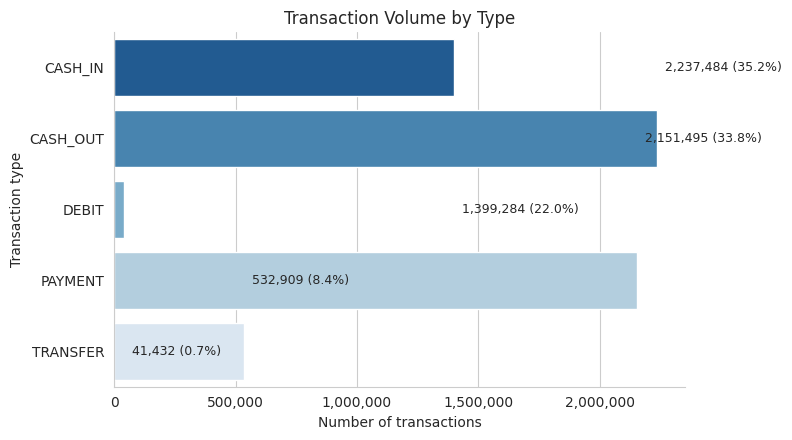

type
CASH_OUT    2237484
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [18]:
type_counts = df_clean["type"].value_counts()

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=type_counts.values, y=type_counts.index, hue=type_counts.index,
            palette="Blues_r", ax=ax, legend=False)
for i, v in enumerate(type_counts.values):
    ax.text(v, i, f"  {v:,} ({v/len(df_clean)*100:.1f}%)", va="center", fontsize=9)
ax.set_xlabel("Number of transactions")
ax.set_ylabel("Transaction type")
ax.set_title("Transaction Volume by Type")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

type_counts


### Interpretation
`CASH_OUT` (35.2%) and `PAYMENT` (33.8%) together make up roughly two-thirds of all transactions.
`DEBIT` is by far the rarest type (0.7%).

### Insight
Any pattern we find for `CASH_OUT` or `PAYMENT` will dominate the overall dataset statistics simply
because of volume — worth remembering when we look at aggregate numbers later.


### 5.2 Univariate: Transaction Amount (Numerical)

**Why log-transform?** We already saw in Section 3 that `amount` is heavily right-skewed (mean far
above median). A raw histogram of a skewed variable like this is dominated by a few huge values, and
the bulk of the data gets compressed into a single bar. Plotting on a **log scale** spreads the data
out and reveals the actual shape of the distribution.


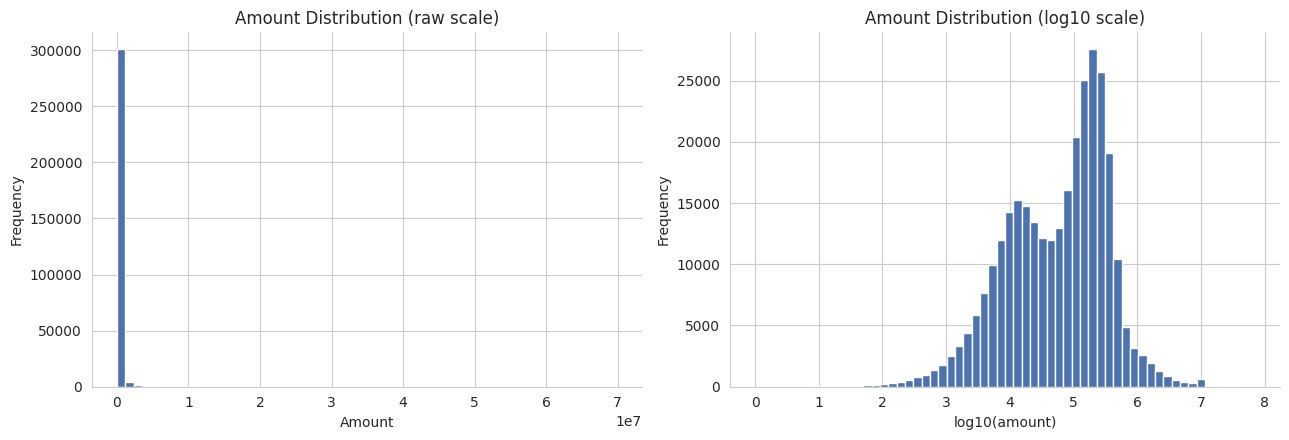

count    6,362,604.00
mean       179,862.38
std        603,858.94
min              0.01
25%         13,389.75
50%         74,872.88
75%        208,721.82
max     92,445,520.00
Name: amount, dtype: float64


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Raw scale
axes[0].hist(df_sample["amount"], bins=60, color=COLOR_MAIN, edgecolor="white")
axes[0].set_title("Amount Distribution (raw scale)")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Frequency")

# Log scale
axes[1].hist(np.log10(df_sample["amount"].clip(lower=1)), bins=60, color=COLOR_MAIN, edgecolor="white")
axes[1].set_title("Amount Distribution (log10 scale)")
axes[1].set_xlabel("log10(amount)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(df_clean["amount"].describe())


### Interpretation
The raw-scale histogram (left) looks like a single spike near zero — almost all the visual "shape" of
the data is hidden because a handful of very large transactions stretch the x-axis. The log-scale
histogram (right) reveals what's really going on: the data is roughly bell-shaped once we account for
its scale, with a mean of about **$179,862** and a median of about **$74,873**.

### Insight
This is a textbook example of why **always plot money/skewed variables on a log scale first**. The raw
histogram alone would have led us to (wrongly) conclude "almost all transactions are near-zero," which
isn't the full picture.


### 5.3 Univariate: The Target Variable — `isFraud`

**Why check this?** Before any fraud-related analysis, we need to know exactly how rare fraud is.
This single number shapes almost every decision in a fraud-detection project — from which metrics to
trust (accuracy is misleading on imbalanced data) to which modeling techniques to use.


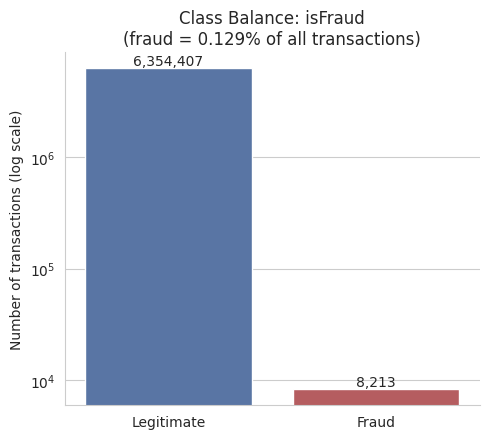

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud rate: 0.1291%


In [20]:
fraud_counts = df["isFraud"].value_counts()   # use full df: every fraud row matters here
fraud_rate = df["isFraud"].mean() * 100

fig, ax = plt.subplots(figsize=(5, 4.5))
sns.barplot(x=["Legitimate", "Fraud"], y=fraud_counts.values, hue=["Legitimate", "Fraud"],
            palette=[COLOR_MAIN, COLOR_FRAUD], ax=ax, legend=False)
ax.set_yscale("log")
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title(f"Class Balance: isFraud\n(fraud = {fraud_rate:.3f}% of all transactions)")
for i, v in enumerate(fraud_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

print(fraud_counts)
print(f"\nFraud rate: {fraud_rate:.4f}%")


### Interpretation
Out of 6,362,620 transactions, only **8,213 (0.129%)** are labeled fraud. Notice we had to use a
**log-scale y-axis** just to make the fraud bar visible at all next to the legitimate bar.

### Insight
This is a **severely imbalanced classification problem**. If we built a naive model that always
predicts "not fraud," it would be 99.87% "accurate" while catching zero fraud — a reminder that
accuracy alone is a meaningless metric here, and that any fraud model needs class-imbalance techniques
(resampling, class weights, or precision/recall-focused metrics) rather than plain accuracy.


### 5.4 Bivariate: Fraud Rate by Transaction Type

**Why?** Now that we know fraud is rare overall, the natural next question is: *does fraud happen
uniformly across transaction types, or is it concentrated somewhere?*


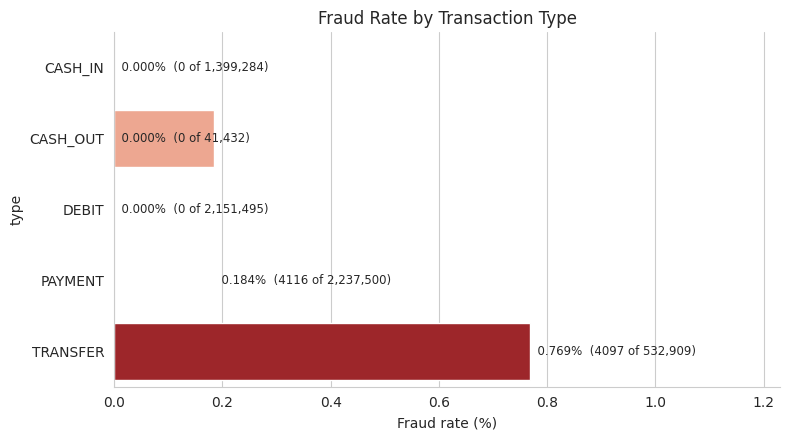

,fraud_count,total_count,fraud_rate,fraud_rate_pct
type,,,,
CASH_IN,0,1399284,0.00,0.00
DEBIT,0,41432,0.00,0.00
PAYMENT,0,2151495,0.00,0.00
CASH_OUT,4116,2237500,0.00,0.18
TRANSFER,4097,532909,0.01,0.77


In [21]:
fraud_by_type = df.groupby("type", observed=True)["isFraud"].agg(["sum", "count", "mean"])
fraud_by_type = fraud_by_type.rename(columns={"sum": "fraud_count", "count": "total_count", "mean": "fraud_rate"})
fraud_by_type["fraud_rate_pct"] = fraud_by_type["fraud_rate"] * 100
fraud_by_type = fraud_by_type.sort_values("fraud_rate_pct", ascending=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=fraud_by_type["fraud_rate_pct"], y=fraud_by_type.index, hue=fraud_by_type.index,
            palette="Reds", ax=ax, legend=False)
for i, (idx, row) in enumerate(fraud_by_type.iterrows()):
    ax.text(row["fraud_rate_pct"], i,
            f"  {row['fraud_rate_pct']:.3f}%  ({int(row['fraud_count'])} of {int(row['total_count']):,})",
            va="center", fontsize=8.5)
ax.set_xlabel("Fraud rate (%)")
ax.set_title("Fraud Rate by Transaction Type")
ax.set_xlim(0, fraud_by_type["fraud_rate_pct"].max() * 1.6)
plt.tight_layout()
plt.show()

fraud_by_type


### Interpretation
Fraud has a **fraud rate of exactly 0%** for `CASH_IN`, `PAYMENT`, and `DEBIT` — it never occurs in
these types at all. It's entirely confined to **`TRANSFER`** (0.769%) and **`CASH_OUT`** (0.183%).

### Insight
This is one of the most actionable findings in the whole analysis: **any fraud detection system for
this dataset can safely ignore 3 of the 5 transaction types**, cutting the search space (and class
imbalance) dramatically. This matches the intuitive fraud pattern the simulation was designed around:
transfer money out, then cash it out.


### 5.5 Bivariate: Transaction Amount vs. Fraud

**Why?** We already saw fraud correlates with "outlier" amounts in Section 4.7. Let's visualize that
relationship directly, comparing the amount distribution for fraud vs. legitimate transactions.


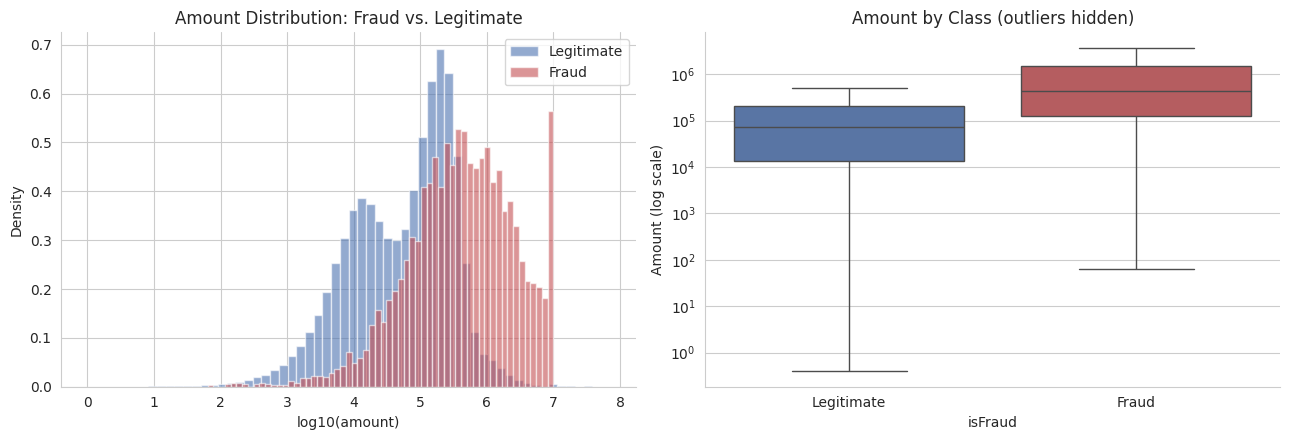

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,"6,354,407.00","178,197.05","596,237.00",0.01,"13,368.40","74,684.72","208,364.77","92,445,520.00"
1,"8,197.00","1,470,832.62","2,405,722.75",63.80,"127,564.33","442,290.22","1,525,742.00","10,000,000.00"


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Overlapping density-style histograms (log scale)
axes[0].hist(np.log10(df_sample.loc[df_sample["isFraud"] == 0, "amount"].clip(lower=1)),
             bins=60, alpha=0.6, label="Legitimate", color=COLOR_MAIN, density=True)
axes[0].hist(np.log10(df_sample.loc[df_sample["isFraud"] == 1, "amount"].clip(lower=1)),
             bins=60, alpha=0.6, label="Fraud", color=COLOR_FRAUD, density=True)
axes[0].set_xlabel("log10(amount)")
axes[0].set_ylabel("Density")
axes[0].set_title("Amount Distribution: Fraud vs. Legitimate")
axes[0].legend()

# Boxplot for a direct summary comparison
sns.boxplot(data=df_sample, x="isFraud", y="amount", hue="isFraud",
            palette=[COLOR_MAIN, COLOR_FRAUD], showfliers=False, ax=axes[1], legend=False)
axes[1].set_yscale("log")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Legitimate", "Fraud"])
axes[1].set_ylabel("Amount (log scale)")
axes[1].set_title("Amount by Class (outliers hidden)")

plt.tight_layout()
plt.show()

df_clean.groupby("isFraud")["amount"].describe()


### Interpretation
The fraud distribution (red) sits visibly to the right of the legitimate distribution (blue) — fraud
transactions tend to involve larger amounts, and the boxplot confirms a higher median for fraud.

### Insight
`amount` alone is a useful (though imperfect) fraud signal — larger transactions are more likely to be
fraudulent, but there's still substantial overlap between the two distributions, so amount by itself
isn't enough to reliably separate fraud from legitimate activity.


### 5.6 Bivariate: The "Account Draining" Pattern

**Why?** Beyond the amount itself, *what happens to the account balance* is a powerful clue. Does a
fraudulent transaction tend to empty the account completely?


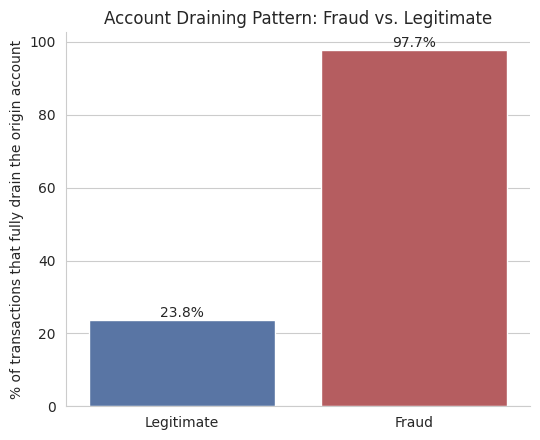

isFraud
0   23.80
1   97.74
Name: drained, dtype: float64


In [23]:
drained = (df_clean["oldbalanceOrg"] > 0) & (df_clean["newbalanceOrig"] == 0)
drain_rate = df_clean.assign(drained=drained).groupby("isFraud")["drained"].mean() * 100

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.barplot(x=["Legitimate", "Fraud"], y=drain_rate.values, hue=["Legitimate", "Fraud"],
            palette=[COLOR_MAIN, COLOR_FRAUD], ax=ax, legend=False)
for i, v in enumerate(drain_rate.values):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
ax.set_ylabel("% of transactions that fully drain the origin account")
ax.set_title("Account Draining Pattern: Fraud vs. Legitimate")
plt.tight_layout()
plt.show()

print(drain_rate)


### Interpretation
**97.7%** of fraudulent transactions leave the origin account at a balance of exactly zero, compared
to only **23.8%** of legitimate transactions.

### Insight
This is the **strongest single behavioral signal** found in this entire analysis — far stronger than
raw amount. It makes intuitive sense: fraud in this simulation is modeled as draining an account
completely, whereas legitimate transactions usually leave some balance behind. Any fraud model built
on this data should include a "did this transaction empty the account?" feature.


### 5.7 Bivariate: Is the Existing Fraud Flag (`isFlaggedFraud`) Any Good?

**Why?** The dataset includes its own simple business rule (`isFlaggedFraud`), meant to catch
large illegal transfers automatically. Since we have the ground truth (`isFraud`), we can directly
measure how well that rule actually performs — a great illustration of **precision vs. recall**.


In [24]:
crosstab = pd.crosstab(df["isFraud"], df["isFlaggedFraud"],
                        rownames=["Actual: isFraud"], colnames=["Rule flagged: isFlaggedFraud"])
print(crosstab)

flagged_fraud = df["isFlaggedFraud"].sum()
true_fraud = df["isFraud"].sum()
caught = ((df["isFraud"] == 1) & (df["isFlaggedFraud"] == 1)).sum()

precision = caught / flagged_fraud * 100 if flagged_fraud else 0
recall = caught / true_fraud * 100 if true_fraud else 0

print(f"\nTotal transactions flagged by the rule: {flagged_fraud}")
print(f"Of those, actually fraud (precision):    {precision:.1f}%")
print(f"Share of ALL fraud that got flagged (recall): {recall:.2f}%")


Rule flagged: isFlaggedFraud        0   1
Actual: isFraud                          
0                             6354407   0
1                                8197  16

Total transactions flagged by the rule: 16
Of those, actually fraud (precision):    100.0%
Share of ALL fraud that got flagged (recall): 0.19%


### Interpretation
The rule only fires **16 times** in the entire dataset of 6.36 million transactions — and every single
one of those 16 is genuinely fraud (**100% precision**). But those 16 are only **0.19%** of the 8,213
actual fraud cases (**recall ≈ 0.2%**).

### Insight
The existing rule is extremely *precise* (it's never wrong when it fires) but has almost no *coverage*
— it misses 99.8% of real fraud. This is a classic precision/recall trade-off, and it shows why relying
on a simple hard-coded threshold rule is not enough: a statistical or machine-learning model is needed
to catch the fraud this rule misses.


### 5.8 Multivariate: Correlation Analysis

**Why?** So far we've looked at variables mostly one or two at a time. A correlation matrix lets us
scan **all numeric relationships at once**, including with our engineered features.

**A caution for beginners:** correlation only captures *linear* relationships. A variable can be a
very strong predictor of fraud through a non-linear or conditional pattern (like the draining pattern
above) while still showing a weak raw correlation coefficient. Don't discard a feature just because its
correlation with the target looks small.


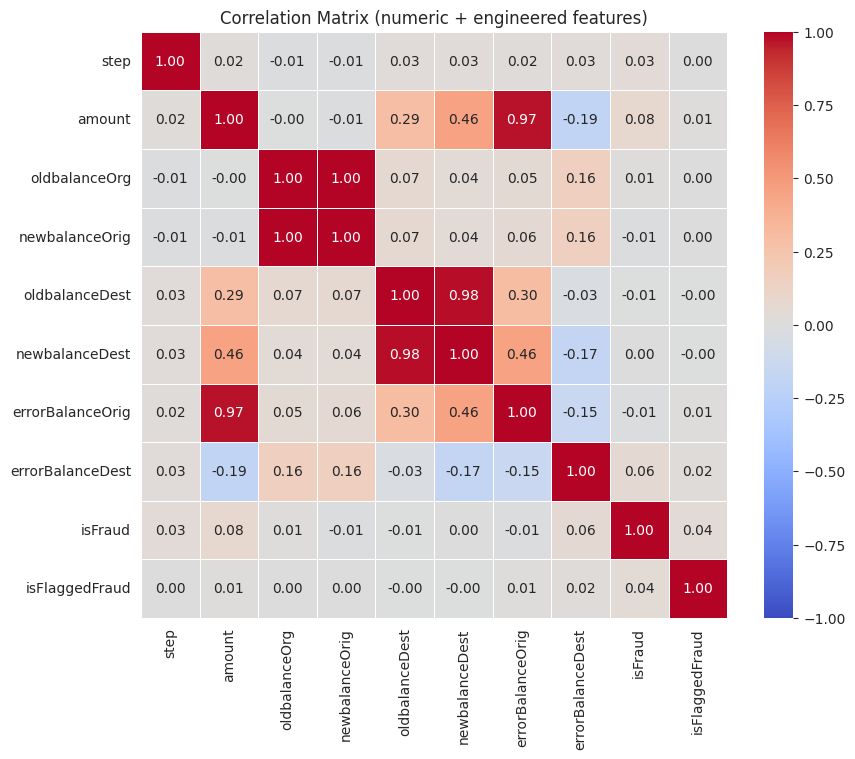

In [25]:
numeric_cols = ["step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest",
                "newbalanceDest", "errorBalanceOrig", "errorBalanceDest", "isFraud", "isFlaggedFraud"]
corr_matrix = df_clean[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Matrix (numeric + engineered features)")
plt.tight_layout()
plt.show()


### Interpretation
`isFraud`'s strongest linear correlations are with `amount` (~0.08) and `errorBalanceDest` (~0.06) —
both positive but weak in absolute terms. `errorBalanceOrig` correlates very strongly with `amount`
itself (~0.97), which makes sense mathematically: for most legitimate transactions the origin balance
update is consistent, so the "error" term ends up tracking the transaction size.

### Insight
Don't be misled by the weak *linear* correlation with `isFraud` — we already found a much stronger
**non-linear** signal in Section 5.6 (the account-draining pattern, 97.7% vs 23.8%) that a simple
correlation coefficient completely fails to capture. This is a valuable lesson: **always complement
correlation analysis with targeted, hypothesis-driven comparisons** like the ones in this notebook.


## 6. Temporal Analysis

### Why
Fraud patterns are often time-dependent (e.g. more attacks at night, or clustered on certain days). The
simulation spans **31 days** (743 hourly steps), which we already broke into `day` and `hour` columns
in Section 4.6.


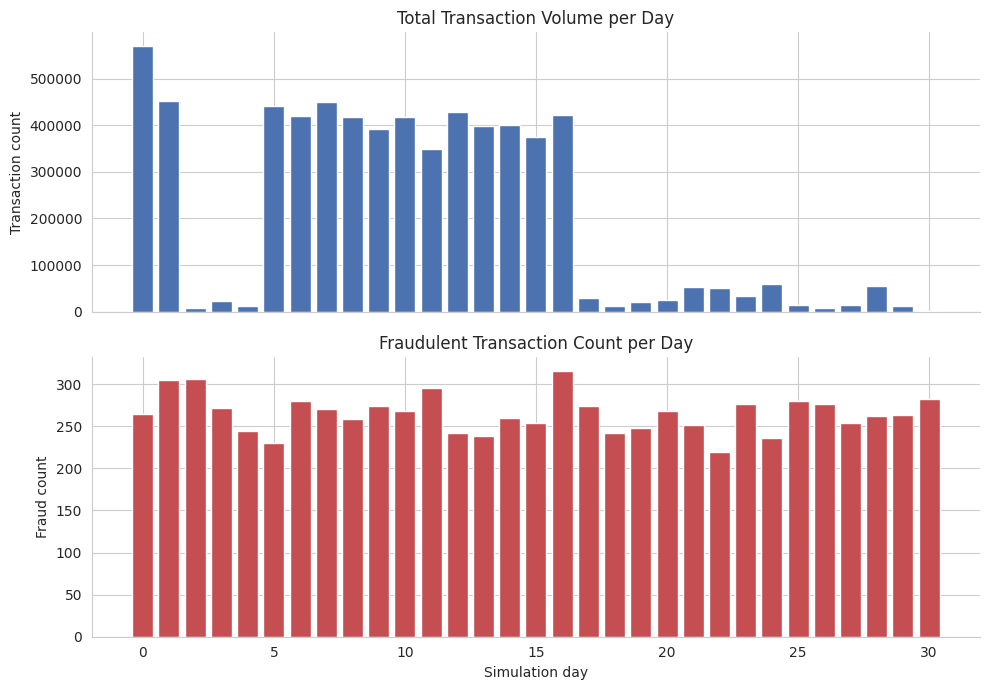

In [26]:
txn_by_day = df_clean.groupby("day")["amount"].agg(count="count", total_amount="sum")
fraud_by_day = df.assign(day=df["step"] // 24).groupby("day")["isFraud"].agg(fraud_count="sum", total="count")
fraud_by_day["fraud_rate_pct"] = fraud_by_day["fraud_count"] / fraud_by_day["total"] * 100

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].bar(txn_by_day.index, txn_by_day["count"], color=COLOR_MAIN)
axes[0].set_ylabel("Transaction count")
axes[0].set_title("Total Transaction Volume per Day")

axes[1].bar(fraud_by_day.index, fraud_by_day["fraud_count"], color=COLOR_FRAUD)
axes[1].set_ylabel("Fraud count")
axes[1].set_xlabel("Simulation day")
axes[1].set_title("Fraudulent Transaction Count per Day")

plt.tight_layout()
plt.show()


### Interpretation
Overall transaction volume is fairly stable day to day (no strong weekly or growth trend visible in a
31-day window). Fraud counts per day fluctuate but don't show an obvious long-term trend either.

### Insight
With only 8,213 fraud cases spread across 31 days (roughly 265 per day on average), day-level
patterns are somewhat noisy. A longer simulation or more fraud examples would be needed to confidently
detect day-of-week or seasonal effects.


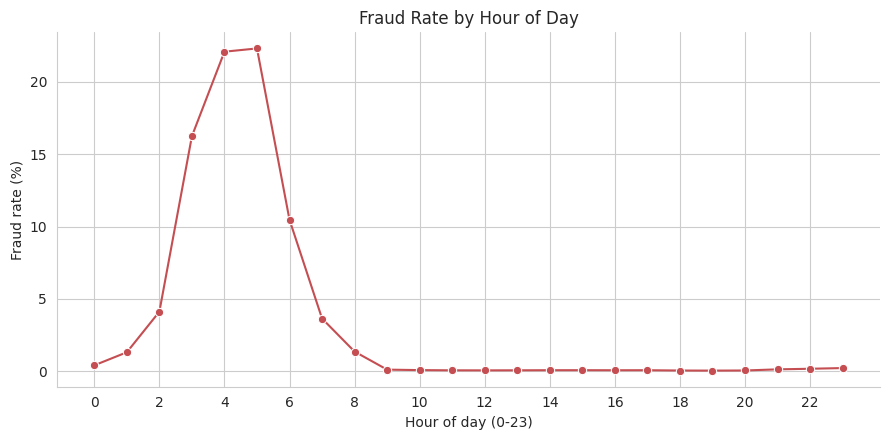

In [27]:
fraud_by_hour = df.assign(hour=df["step"] % 24).groupby("hour")["isFraud"].agg(fraud_count="sum", total="count")
fraud_by_hour["fraud_rate_pct"] = fraud_by_hour["fraud_count"] / fraud_by_hour["total"] * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(x=fraud_by_hour.index, y=fraud_by_hour["fraud_rate_pct"], marker="o", color=COLOR_FRAUD, ax=ax)
ax.set_xlabel("Hour of day (0-23)")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud Rate by Hour of Day")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()


### Interpretation
Fraud rate fluctuates across the 24 hours without one single hour standing out dramatically — again,
consistent with the relatively small number of total fraud cases available at hourly granularity.

### Insight
Time-of-day doesn't appear to be a strong standalone predictor of fraud in this dataset. This is a
useful negative result: it tells us not to over-invest modeling effort in hour-of-day features, and to
focus instead on the stronger signals we already found (transaction type, amount, and the
account-draining pattern).


## 7. Key Insights Summary

Pulling everything together, here is what this cleaning and EDA process revealed about the PaySim
dataset:

**Data quality**
- The dataset is remarkably clean: no missing values, no duplicate rows, no negative amounts.
- The only quality issue found was 16 zero-amount transactions — and every one of them was fraud,
  making them worth keeping rather than blindly discarding.

**Fraud characteristics**
- Fraud is extremely rare (0.13% of transactions) but disproportionately high-value (about 1% of
  total transaction value).
- Fraud occurs **only** in `TRANSFER` and `CASH_OUT` transactions — never in `CASH_IN`, `PAYMENT`, or
  `DEBIT`.
- The single strongest behavioral signal is **account draining**: 97.7% of fraud transactions empty
  the origin account completely, versus 23.8% of legitimate ones.
- The dataset's built-in `isFlaggedFraud` rule is precise (100%) but catches under 0.2% of real fraud
  — essentially non-functional as a standalone detection system.
- Linear correlation with `isFraud` is weak across all raw fields — the real signal lives in
  engineered, non-linear features (like account draining), not the raw numbers.

**Structural facts about the data**
- Merchant accounts (`M` prefix) only ever appear as the destination of `PAYMENT` transactions, and
  their balances are never tracked (always recorded as 0) — a simulation artifact, not an error.
- Almost every origin account transacts only once in the 31-day window.


## 8. Conclusion & Recommended Next Steps

This notebook walked through a complete, beginner-friendly data cleaning and EDA workflow: profiling
the raw data, systematically checking and resolving quality issues, engineering new features, and
exploring the data from univariate, bivariate, multivariate, and temporal angles — always pairing code
with *why* we ran it and *what* the output actually means.

If you wanted to take this further (e.g. toward building a fraud detection model), reasonable next
steps would be:

1. Restrict modeling to `TRANSFER` and `CASH_OUT` transactions only, since fraud never occurs elsewhere.
2. Use the account-draining feature (and similar engineered features) explicitly — raw correlation
   understates their value.
3. Address the severe class imbalance with resampling (e.g. SMOTE) or class weighting before training
   any classifier.
4. Evaluate models with precision, recall, and F1-score (or PR-AUC) rather than accuracy, given how
   rare fraud is.
5. Retain the 16 zero-amount fraud rows in any labeled training set, even though they were excluded
   from the general distribution statistics above.
6. Note that this EDA computed features like `errorBalanceOrig`, `errorBalanceDest`, and the
   account-draining flag using each transaction's own `oldbalance`/`newbalance` fields — values only
   known *after* the transaction completes. Before training, confirm these same fields are available
   at prediction time in your real pipeline (they are here, since PaySim logs pre- and post-transaction
   balances together), and always fit any train/test split or resampling **after** separating train
   and test data, never before, to avoid leaking information between them.
